# Tarea: el paisaje de pérdida de tu propia red

En esta tarea vas a usar **losslens** para visualizar la función de pérdida alrededor de una red que
**entrenaste en una tarea anterior**, y a explicar lo que ves.

No necesitas saber cómo funciona losslens por dentro. Solo necesitas estas llamadas:

```python
surf = losslens.surface(model, data, loss_fn=nn.CrossEntropyLoss())   # calcular
surf.plot()   surf.plot_3d()   surf.plot_slice()                      # visualizar
surf.summary()                                                        # números
losslens.compare({"A": surf_a, "B": surf_b})                          # comparar
surf.save("a.npz");  surf = losslens.load("a.npz")                    # guardar
```

Documentación completa: https://github.com/iturbideM/losslens

**Qué entregar:** este notebook, ejecutado de principio a fin, con cada *Tu respuesta aquí*
reemplazado por tu respuesta. Las respuestas deben ser breves (unas pocas oraciones) y hacer
referencia a tus gráficas y números.

**Consejos**

- Usa un entorno con GPU (en Colab: *Entorno de ejecución → Cambiar tipo de entorno de ejecución → GPU*).
- Prueba primero con una `resolution` baja (por ejemplo 11) para verificar que todo funciona, y luego
  usa el valor por defecto para tus figuras finales.
- Pásale a losslens datos **sin aumento de datos** (*data augmentation*).
- Guarda cada superficie que calcules con `surf.save(...)`, por si el notebook se reinicia.

## Preparación

In [2]:
%pip install -q git+https://github.com/iturbideM/losslens

Note: you may need to restart the kernel to use updated packages.


In [3]:
import os
import time

import torch
import torch.nn as nn
import torch.nn.functional as F
import losslens
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

# Para probar rápido bajar RES a 11. Para las figuras finales dejar 25 (el valor por defecto)
RES = 25

# Acá se guardan los pesos y las superficies, así si se reinicia el kernel no hay que recalcular todo
os.makedirs("resultados", exist_ok=True)

device: cuda


## Parte 1: Tu modelo y tus datos

Carga (o vuelve a entrenar) la red de tu tarea anterior y los datos con los que fue entrenada.

1. Define la clase de tu modelo y carga sus pesos entrenados.
2. Construye un DataLoader, un Dataset o tensores `(X, y)` con tus datos de **entrenamiento**, sin
   aumento de datos.
3. Escribe la función de pérdida con la que entrenaste.

Si tus batches no son de la forma `(inputs, targets)`, o tu pérdida no es
`loss_fn(model(inputs), targets)`, vas a necesitar `forward=` en lugar de `loss_fn=` (ver la
documentación).

In [4]:
# Tu modelo
# CNN chica para Fashion MNIST: dos bloques conv + relu + maxpool y después dos capas lineales
class CNN(nn.Module):
    def __init__(self, n_clases=10):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 32, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.fc1 = nn.Linear(64 * 7 * 7, 128)
        self.fc2 = nn.Linear(128, n_clases)

    def forward(self, x):
        x = F.max_pool2d(F.relu(self.conv1(x)), 2)   # 28x28 -> 14x14
        x = F.max_pool2d(F.relu(self.conv2(x)), 2)   # 14x14 -> 7x7
        x = x.flatten(1)
        x = F.relu(self.fc1(x))
        return self.fc2(x)


print(CNN())
print("parámetros:", sum(p.numel() for p in CNN().parameters()))

CNN(
  (conv1): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (fc1): Linear(in_features=3136, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)
parámetros: 421642


In [5]:
# Tus datos
# Solo ToTensor y normalización, sin data augmentation
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.2860,), (0.3530,)),
])

train_data = datasets.FashionMNIST(root="./data", train=True, download=True, transform=transform)
test_data = datasets.FashionMNIST(root="./data", train=False, download=True, transform=transform)

clases = train_data.classes
print(len(train_data), "imágenes de train,", len(test_data), "de test")
print(clases)

test_loader = DataLoader(test_data, batch_size=1000, shuffle=False)

100%|██████████| 26.4M/26.4M [00:03<00:00, 7.07MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 63.3kB/s]
100%|██████████| 4.42M/4.42M [00:02<00:00, 1.72MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 40.5MB/s]

60000 imágenes de train, 10000 de test
['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


In [6]:
# Tu función de pérdida
loss_fn = nn.CrossEntropyLoss()

In [7]:
# Entrenamiento del modelo base (si ya existen los pesos los carga)
EPOCHS = 15
LR = 0.02


def entrenar(batch_size, epochs=EPOCHS, lr=LR, seed=0):
    torch.manual_seed(seed)
    model = CNN().to(device)
    opt = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9)
    loader = DataLoader(train_data, batch_size=batch_size, shuffle=True,
                        num_workers=2, pin_memory=(device == "cuda"))
    for ep in range(epochs):
        model.train()
        t0, total, n = time.time(), 0.0, 0
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            loss = loss_fn(model(x), y)
            opt.zero_grad()
            loss.backward()
            opt.step()
            total += loss.item() * len(y)
            n += len(y)
        print(f"  época {ep + 1:2d}/{epochs}  loss train {total / n:.4f}  ({time.time() - t0:.1f}s)")
    return model


@torch.no_grad()
def evaluar(model, loader):
    model.eval()
    total, correctos, n = 0.0, 0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        out = model(x)
        total += loss_fn(out, y).item() * len(y)
        correctos += (out.argmax(1) == y).sum().item()
        n += len(y)
    return total / n, correctos / n


def entrenar_o_cargar(nombre, batch_size):
    ruta = f"resultados/{nombre}.pt"
    if os.path.exists(ruta):
        model = CNN().to(device)
        model.load_state_dict(torch.load(ruta, map_location=device))
        print("cargado", ruta)
    else:
        print(f"entrenando {nombre} (batch_size={batch_size})")
        model = entrenar(batch_size)
        torch.save(model.state_dict(), ruta)
    model.eval()
    return model


model = entrenar_o_cargar("cnn_bs64", batch_size=64)

# Para medir en train sin shuffle
train_eval_loader = DataLoader(train_data, batch_size=1000, shuffle=False)
loss_tr, acc_tr = evaluar(model, train_eval_loader)
loss_te, acc_te = evaluar(model, test_loader)
print(f"train: loss {loss_tr:.4f}  acc {acc_tr:.4f}")
print(f"test:  loss {loss_te:.4f}  acc {acc_te:.4f}")

entrenando cnn_bs64 (batch_size=64)
  época  1/15  loss train 0.4397  (10.9s)
  época  2/15  loss train 0.2655  (9.8s)
  época  3/15  loss train 0.2201  (9.8s)
  época  4/15  loss train 0.1947  (10.0s)
  época  5/15  loss train 0.1703  (10.5s)
  época  6/15  loss train 0.1524  (10.2s)
  época  7/15  loss train 0.1330  (10.1s)
  época  8/15  loss train 0.1123  (10.3s)
  época  9/15  loss train 0.1010  (10.0s)
  época 10/15  loss train 0.0882  (10.1s)
  época 11/15  loss train 0.0790  (10.5s)
  época 12/15  loss train 0.0665  (10.1s)
  época 13/15  loss train 0.0572  (9.9s)
  época 14/15  loss train 0.0531  (9.9s)
  época 15/15  loss train 0.0470  (9.8s)
train: loss 0.0463  acc 0.9828
test:  loss 0.4021  acc 0.9121


## Parte 2: El paisaje de tu modelo

Calcula el paisaje alrededor de tu modelo entrenado con las opciones por defecto, y muestra la
gráfica de contorno, la gráfica 3D y los cortes. Luego imprime el resumen.

In [8]:
# Calcular la superficie
def superficie(nombre, model, **kwargs):
    """Calcula la superficie o la carga si ya está guardada."""
    ruta = f"resultados/{nombre}.npz"
    if os.path.exists(ruta):
        s = losslens.load(ruta)
        if s.meta["resolution"] == (RES if RES % 2 else RES + 1):
            print("cargada", ruta)
            return s
    s = losslens.surface(model, train_data, loss_fn=loss_fn, resolution=RES, **kwargs)
    s.save(ruta)
    return s


surf = superficie("base_seed0", model)
surf

Evaluating 625 points on 2000 examples (estimated time: 5 s).


Surface(25x25 grid, scale=1.0, center_loss=0.04993)

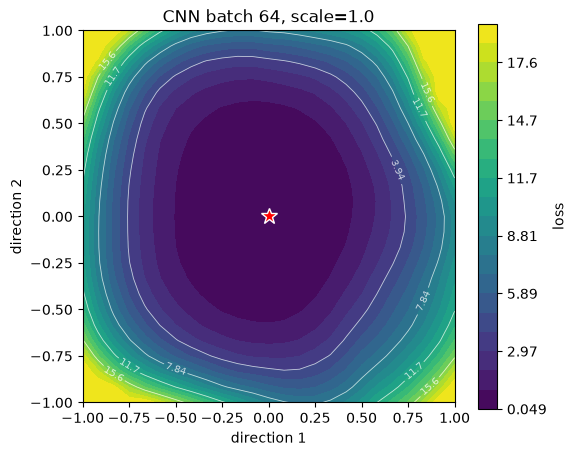

In [9]:
# Gráfica de contorno
surf.plot(title="CNN batch 64, scale=1.0")

In [10]:
# Gráfica 3D
surf.plot_3d(title="CNN batch 64, scale=1.0")

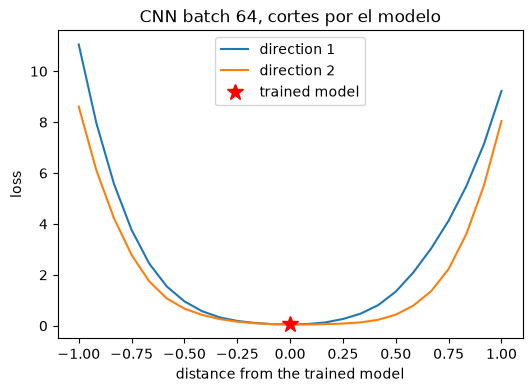

In [11]:
# Cortes
surf.plot_slice(title="CNN batch 64, cortes por el modelo")

In [12]:
# Resumen
res_base = surf.summary()

CNN  (scale=1.0, 2000 examples)
  loss of the trained model                     0.04993
  lowest loss on the grid                       0.04901
  where it is (direction 1, direction 2)        (+0.00, +0.08)
  is the trained model the lowest point?        no
  mean loss increase at 10% of scale            0.02053
  mean loss increase at 25% of scale            0.1333
  mean loss increase at 50% of scale            0.8227
  steeper / flatter direction, at 50% of scale  2.189


**2.1** Describe la forma del paisaje. ¿Está el modelo entrenado en el fondo de un valle? ¿El
valle es ancho o angosto, redondo o alargado, suave o irregular?

Sí, el modelo está en el fondo de un valle. En el contorno la estrella queda en el centro de la zona más oscura y la loss sube hacia todos lados. El valle es ancho y suave, con curvas de nivel casi concéntricas y sin otros pozos ni saltos raros. No es del todo redondo, está un poco estirado en la dirección 2. En los cortes se ve lo mismo. Hasta una distancia de 0.25 la loss casi no se mueve, y de ahí en adelante sube rápido hasta 11 en el extremo de la dirección 1 y unos 8.5 en la dirección 2.

**2.2** Usa los números de `summary()` para respaldar tu descripción.

La loss del modelo es 0.0499 y el mínimo de la grilla es 0.0490 en (0, +0.08). El summary dice que el modelo no es el punto más bajo, pero la diferencia es de 0.001 y está a un solo paso de la grilla, así que en la práctica está en el fondo. El aumento medio de la loss es 0.021 al 10% de la escala, 0.133 al 25% y 0.82 al 50%. O sea que cerca del modelo es bastante plano, y entre el 25% y el 50% la subida se multiplica por 6, que es la forma de cuenco que se ve en los cortes. El cociente entre la dirección más empinada y la más plana es 2.19, que confirma que el valle es alargado.

## Parte 3: ¿Es una forma real?

Las dos direcciones son aleatorias. Calcula el paisaje de nuevo con otra `seed`, y compara ambos
con `losslens.compare`.

Evaluating 625 points on 2000 examples (estimated time: 4 s).


                                                    seed 0        seed 1
loss of the trained model                          0.04993       0.04261
lowest loss on the grid                            0.04901       0.04261
where it is (direction 1, direction 2)        (+0.00, +0.08)  (+0.00, +0.00)
is the trained model the lowest point?                  no           yes
mean loss increase at 10% of scale                 0.02053        0.0154
mean loss increase at 25% of scale                  0.1333        0.1075
mean loss increase at 50% of scale                  0.8227        0.6552
steeper / flatter direction, at 50% of scale         2.189         1.759


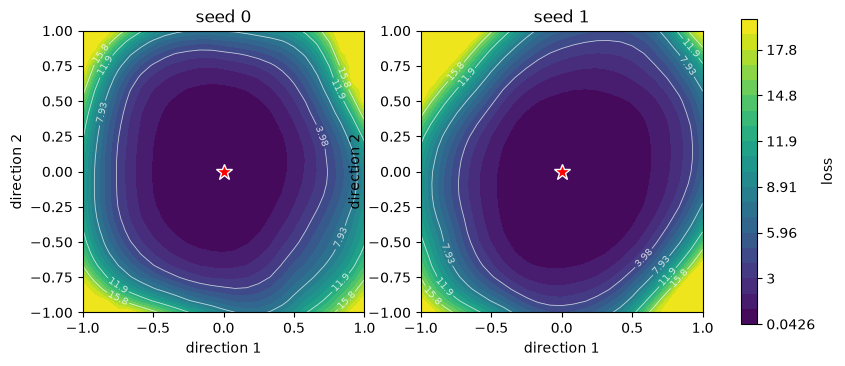

In [13]:
# Segunda semilla y comparación
surf_s1 = superficie("base_seed1", model, seed=1)
losslens.compare({"seed 0": surf, "seed 1": surf_s1})

**3.1** ¿Se parecen los dos paisajes? ¿Qué te dice eso sobre tu respuesta a la Parte 2?

Sí, se parecen bastante. En los dos hay un único valle con el modelo en el centro, y las curvas de nivel aparecen más o menos a la misma distancia (la de loss 4 anda cerca de 0.6 en los dos). Los números van en la misma línea, con un aumento al 50% de 0.82 contra 0.66 y un cociente de 2.19 contra 1.76. Con la semilla 1 el modelo sí es el punto más bajo de la grilla. La loss del centro cambia un poco (0.050 y 0.043) porque la semilla también cambia el subconjunto de 2000 ejemplos.

Lo que no se repite es hacia dónde se estira el valle. Con la semilla 0 es vertical y con la 1 queda en diagonal. Eso depende de las direcciones que salieron sorteadas. Entonces lo que dije en la Parte 2 sobre el valle ancho, suave y con el modelo en el fondo parece ser una propiedad real de la red. Lo del alargamiento lo tomaría con más cuidado, aunque en las dos semillas el cociente da entre 1.7 y 2.2, así que algo de asimetría hay.

## Parte 4: Acercar y alejar

Calcula el paisaje con al menos otros dos valores de `scale`, uno menor y otro mayor que 1.0, y
grafícalos.

Evaluating 625 points on 2000 examples (estimated time: 4 s).


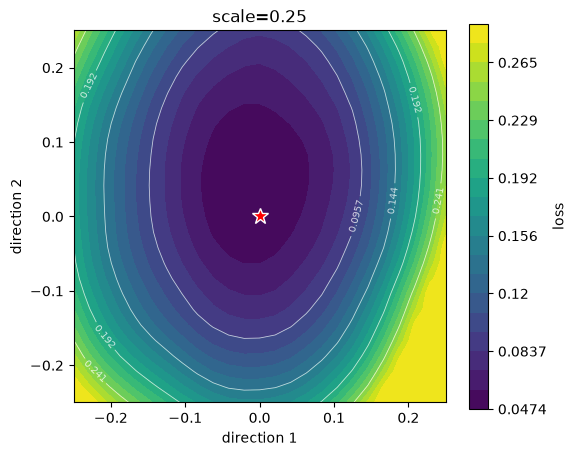

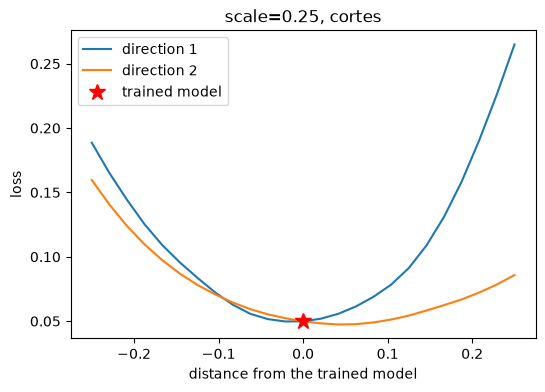

CNN  (scale=0.25, 2000 examples)
  loss of the trained model                     0.04993
  lowest loss on the grid                       0.0474
  where it is (direction 1, direction 2)        (+0.00, +0.04)
  is the trained model the lowest point?        no
  mean loss increase at 10% of scale            0.001057
  mean loss increase at 25% of scale            0.006348
  mean loss increase at 50% of scale            0.02721
  steeper / flatter direction, at 50% of scale  2.303


In [14]:
# Escala menor
surf_chica = superficie("base_scale025", model, scale=0.25)
display(surf_chica.plot(title="scale=0.25"))
display(surf_chica.plot_slice(title="scale=0.25, cortes"))
res_chica = surf_chica.summary()

Evaluating 625 points on 2000 examples (estimated time: 4 s).


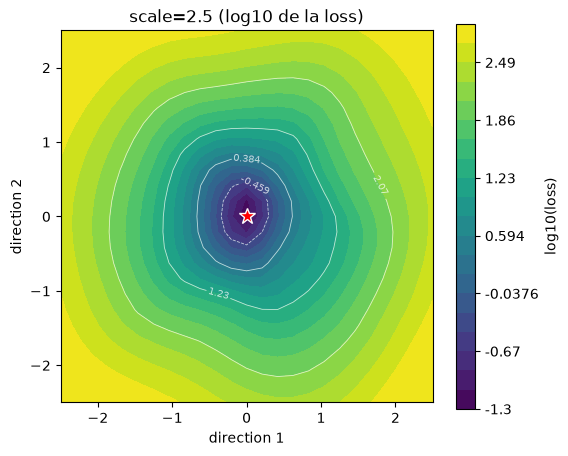

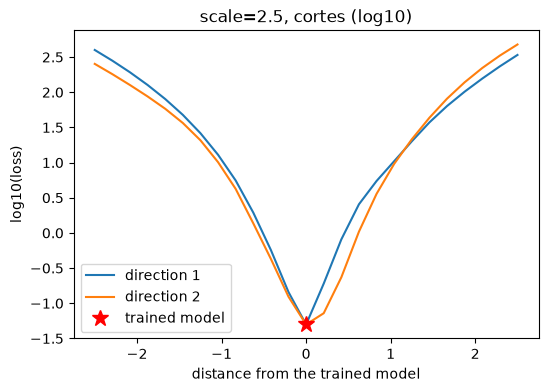

CNN  (scale=2.5, 2000 examples)
  loss of the trained model                     0.04993
  lowest loss on the grid                       0.04993
  where it is (direction 1, direction 2)        (+0.00, +0.00)
  is the trained model the lowest point?        yes
  mean loss increase at 10% of scale            0.1693
  mean loss increase at 25% of scale            1.822
  mean loss increase at 50% of scale            21.73
  steeper / flatter direction, at 50% of scale  1.096


In [15]:
# Escala mayor
# Lejos del mínimo la loss crece mucho, así que la miro también en escala log
surf_grande = superficie("base_scale25", model, scale=2.5)
display(surf_grande.plot(log=True, title="scale=2.5 (log10 de la loss)"))
display(surf_grande.plot_slice(log=True, title="scale=2.5, cortes (log10)"))
res_grande = surf_grande.summary()

**4.1** ¿Qué ves en cada escala? ¿Qué valor de `scale` muestra mejor el paisaje de tu modelo, y
por qué?

Con scale 0.25 es como hacer zoom al fondo del valle. La loss va de 0.047 a 0.27 y el aumento al 50% es apenas 0.027. A esta escala se ven detalles que antes no se notaban. El mínimo de la grilla está un poquito corrido, en (0, +0.04), y la dirección 2 es mucho más plana que la 1 (cociente 2.3). En los cortes la dirección 1 tampoco es simétrica, sube a 0.27 en +0.25 y a 0.19 en -0.25.

Con scale 2.5 tuve que usar escala logarítmica porque la loss llega a varios cientos en los bordes (10^2.5) y el aumento al 50% es 21.7. El valle queda como un pozo chiquito en el medio, rodeado de una meseta muy alta. En los cortes en log la subida es casi una recta desde el centro, o sea que la loss crece más o menos exponencial, y las dos direcciones son casi iguales (cociente 1.1).

Para mí la que mejor muestra el paisaje es scale 1.0. Ahí se ve el valle completo, el fondo plano y dónde empieza a subir la loss. Con 0.25 solo se ve el fondo, que parece una parábola cualquiera, y con 2.5 casi todo el gráfico es una zona donde la red ya no sirve y el valle se reduce a un punto.

## Parte 5: Comparar dos modelos

Entrena una **segunda versión** de tu modelo que difiera en una sola cosa, y compara los dos
paisajes con `losslens.compare`. Algunas ideas:

- con y sin *weight decay* (u otra regularización, por ejemplo dropout);
- tamaño de batch chico vs. grande;
- con y sin conexiones residuales (*skip connections*) o BatchNorm;
- una versión angosta vs. una ancha de la red;
- un checkpoint temprano vs. el modelo final.

Usa los mismos `scale` y `n_samples` para ambos.

In [16]:
# Entrenar el segundo modelo
# Lo único que cambia es el tamaño de batch: 2048 en vez de 64 (mismo lr, épocas, optimizador y semilla)
model_bs2048 = entrenar_o_cargar("cnn_bs2048", batch_size=2048)

entrenando cnn_bs2048 (batch_size=2048)
  época  1/15  loss train 1.5166  (9.5s)
  época  2/15  loss train 0.7023  (9.5s)
  época  3/15  loss train 0.5005  (9.5s)
  época  4/15  loss train 0.4410  (9.5s)
  época  5/15  loss train 0.4103  (9.5s)
  época  6/15  loss train 0.3756  (9.6s)
  época  7/15  loss train 0.3540  (9.6s)
  época  8/15  loss train 0.3473  (9.5s)
  época  9/15  loss train 0.3376  (9.5s)
  época 10/15  loss train 0.3194  (10.2s)
  época 11/15  loss train 0.3091  (10.5s)
  época 12/15  loss train 0.2990  (10.3s)
  época 13/15  loss train 0.2897  (9.9s)
  época 14/15  loss train 0.2895  (9.9s)
  época 15/15  loss train 0.2781  (9.8s)


Evaluating 625 points on 2000 examples (estimated time: 4 s).


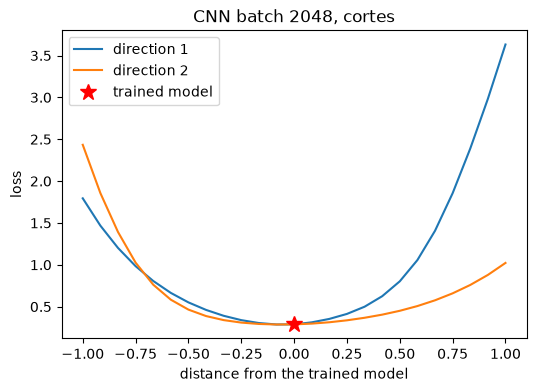

                                                  batch 64    batch 2048
loss of the trained model                          0.04993        0.2884
lowest loss on the grid                            0.04901        0.2869
where it is (direction 1, direction 2)        (+0.00, +0.08)  (+0.00, -0.08)
is the trained model the lowest point?                  no            no
mean loss increase at 10% of scale                 0.02053        0.0128
mean loss increase at 25% of scale                  0.1333       0.06373
mean loss increase at 50% of scale                  0.8227        0.2794
steeper / flatter direction, at 50% of scale         2.189         2.295


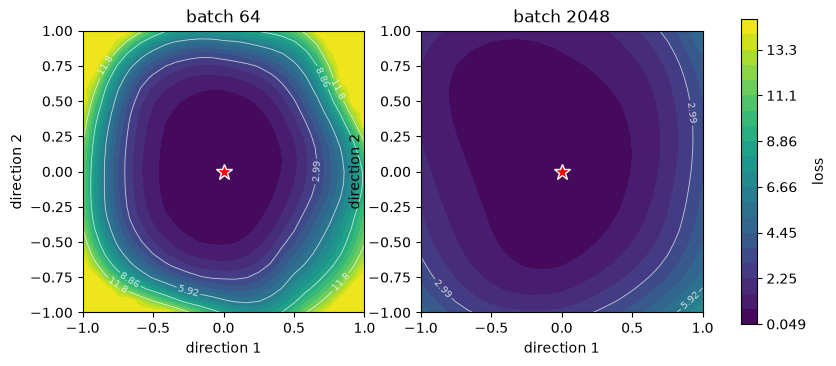

In [17]:
# Calcular su paisaje y comparar
# Mismo scale (1.0) y n_samples (2000) que el modelo base
surf_bs2048 = superficie("bs2048_seed0", model_bs2048)
display(surf_bs2048.plot_slice(title="CNN batch 2048, cortes"))
losslens.compare({"batch 64": surf, "batch 2048": surf_bs2048})

**5.1** ¿Qué cambiaste, y qué esperabas ver?

Cambié el tamaño de batch, de 64 a 2048. Todo lo demás quedó igual (SGD con lr 0.02 y momentum 0.9, 15 épocas, misma semilla). Esperaba que el batch grande terminara en un mínimo más angosto y el batch chico en uno más ancho, porque el ruido del gradiente con batches chicos ayuda a escaparse de los mínimos angostos. También esperaba que el de batch 2048 quedara menos entrenado, porque hace unos 30 pasos por época contra 938, es decir 450 pasos en total contra unos 14000.

**5.2** ¿Qué ves realmente? Usa las gráficas y la tabla del resumen.

Salió al revés de lo que esperaba, el de batch 2048 es más plano. Con la misma escala de colores el paisaje de batch 2048 es casi todo oscuro y la loss no pasa de 3 en casi toda la grilla, mientras que el de batch 64 llega a más de 13 en las esquinas. En el summary el aumento medio al 10%, 25% y 50% es 0.021, 0.133 y 0.82 para batch 64, contra 0.013, 0.064 y 0.28 para batch 2048. El cociente es parecido en los dos (2.19 y 2.30), así que los dos valles son igual de alargados.

El problema es que el modelo de batch 2048 está en otro lugar. Su loss en el centro es 0.288, contra 0.050 del de batch 64, o sea que no llegó al fondo del valle y quedó en una zona más alta y más abierta. Mirado en relación a su propia loss, al 50% el de batch 64 multiplica su loss por 17 y el de batch 2048 apenas la duplica. Creo que parte de esto es que con loss 0.05 la red está muy segura de sus predicciones, y cuando los pesos se mueven y empieza a equivocarse la cross entropy castiga mucho esos errores.

In [18]:
# Desempeño en train y test de los dos modelos
print(f"{'modelo':<12}{'loss train':>12}{'acc train':>11}{'loss test':>11}{'acc test':>10}")
for nombre, m in [("batch 64", model), ("batch 2048", model_bs2048)]:
    l_tr, a_tr = evaluar(m, train_eval_loader)
    l_te, a_te = evaluar(m, test_loader)
    print(f"{nombre:<12}{l_tr:>12.4f}{a_tr:>11.4f}{l_te:>11.4f}{a_te:>10.4f}")

modelo        loss train  acc train  loss test  acc test
batch 64          0.0463     0.9828     0.4021    0.9121
batch 2048        0.2722     0.9028     0.3066    0.8897


**5.3** Compara con el desempeño en test de ambos modelos. En tu caso, ¿un paisaje más plano
va de la mano con un mejor desempeño en test?

En test el de batch 64 tiene 91.2% de accuracy y loss 0.402. El de batch 2048 tiene 89.0% y loss 0.307. En accuracy gana el modelo más empinado por 2.2 puntos, así que en mi caso un paisaje más plano no vino con mejor desempeño en test. En loss de test sí gana el más plano, y su diferencia entre train y test es mucho menor (90.3% contra 89.0%, cuando el de batch 64 va de 98.3% a 91.2%). El de batch 64 está sobreajustando bastante.

Igual no me parece una comparación justa, porque el de batch 2048 es más plano sobre todo porque está menos entrenado y no porque haya encontrado un mínimo mejor. Para sacar una conclusión habría que entrenarlo hasta una loss de train parecida, con más épocas o escalando el learning rate.

## Parte 6: Conclusiones

**6.1** En unas pocas oraciones: ¿qué aprendiste sobre tu red a partir de su paisaje de pérdida?

Mi CNN quedó en el fondo de un valle único, ancho y suave, y esa forma se mantiene al cambiar las direcciones aleatorias. Cerca del modelo es bastante plano (mover los pesos un 25% de su tamaño sube la loss 0.13), pero después la loss crece muy rápido y a escala 2.5 ya está en los cientos. También aprendí que la planitud sola no alcanza para predecir cómo le va en test. El modelo de batch grande era más plano y generalizaba con menos diferencia entre train y test, pero tenía peor accuracy porque estaba menos entrenado. Para comparar paisajes de dos modelos hay que fijarse primero en que estén en un punto parecido del entrenamiento, si no la comparación mezcla cosas distintas.